# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ansh-Saraswat-PC/FlyRank/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [2]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 6.0 MB/s  0:00:016.0 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 7.0 MB/s  0:00:00m 7.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 6.9 MB/s  0:00:006.9 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

The Playbook: Striking Distance Content Recovery
This queue translates the Random Forest probability scores into specific operational tasks for the editorial team. Pages are sorted by their ML likelihood of being a "refresh opportunity" (high volume, severely broken CTR).
Actions:
PRIORITY_REFRESH: ML Probability > 0.70. These pages are mathematically bleeding traffic.
REVIEW_METADATA: ML Probability 0.50 - 0.70. These pages have marginal decay; check title tags before rewriting content.
MONITOR: ML Probability < 0.50. Leave these alone; they are performing within expected boundaries.
Reason Codes:
HIGH_VOL_STRIKING_DISTANCE: Impressions are in the top quartile, but position is 11-20.
SEVERE_CTR_DECAY: Position is Page 1, but CTR is uncharacteristically near zero.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import duckdb
import pandas as pd
import os
import getpass
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Setup & Auth
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
hf_token = os.environ.get('HF_TOKEN')
if not hf_token:
    hf_token = getpass.getpass("HF_TOKEN not found in env. Paste your Hugging Face READ token here: ")
con.execute(f"CREATE SECRET (TYPE HUGGINGFACE, TOKEN '{hf_token}');")

# 2. Load & Prepare Data (Self-contained for this notebook)
hf_path = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/*.parquet"
df_playbook = con.sql(f"""
    SELECT 
        content_hash_id,
        SUM(gsc_impressions) as impressions,
        SUM(gsc_clicks) as clicks,
        AVG(gsc_avg_position) as position,
        SUM(sessions_organic) as sessions
    FROM '{hf_path}'
    WHERE gsc_impressions > 100
    GROUP BY content_hash_id
""").df()

# 3. Train Model & Score Queue
df_playbook['ctr'] = df_playbook['clicks'] / df_playbook['impressions']
imp_median = df_playbook['impressions'].median()
y = ((df_playbook['impressions'] > imp_median) & (df_playbook['ctr'] < 0.01)).astype(int)
X = df_playbook[['impressions', 'clicks', 'position', 'sessions']]

rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf.fit(X, y)
df_playbook['ml_score'] = rf.predict_proba(X)[:, 1]

# 4. Map Actions & Reason Codes
def assign_action(row):
    if row['ml_score'] > 0.70: return 'PRIORITY_REFRESH'
    if row['ml_score'] > 0.50: return 'REVIEW_METADATA'
    return 'MONITOR'

def assign_reason(row):
    if row['impressions'] > imp_median and 11 <= row['position'] <= 20: return 'HIGH_VOL_STRIKING_DISTANCE'
    if row['position'] <= 10 and row['ctr'] < 0.01: return 'SEVERE_CTR_DECAY'
    return 'STANDARD_PERFORMANCE'

df_playbook['action'] = df_playbook.apply(assign_action, axis=1)
df_playbook['reason_code'] = df_playbook.apply(assign_reason, axis=1)

# Sort the final queue
df_queue = df_playbook[df_playbook['action'] != 'MONITOR'].sort_values('ml_score', ascending=False)
print(f"Playbook generated: {len(df_queue)} actionable pages.")
print(df_queue[['content_hash_id', 'action', 'reason_code', 'ml_score']].head(5))

Matplotlib is building the font cache; this may take a moment.


HF_TOKEN not found in env. Paste your Hugging Face READ token here:  ········


Playbook generated: 19683 actionable pages.
                content_hash_id            action           reason_code  \
33757  content_6177aad2ded9dee5  PRIORITY_REFRESH  STANDARD_PERFORMANCE   
27877  content_19c9547dd904c577  PRIORITY_REFRESH  STANDARD_PERFORMANCE   
37977  content_af748217e2ec86bc  PRIORITY_REFRESH  STANDARD_PERFORMANCE   
14089  content_2da022341f8803c3  PRIORITY_REFRESH  STANDARD_PERFORMANCE   
29269  content_bcc7a834b74b996b  PRIORITY_REFRESH  STANDARD_PERFORMANCE   

       ml_score  
33757   0.99992  
27877   0.99992  
37977   0.99992  
14089   0.99992  
29269   0.99992  


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

Intended Use:
This playbook is a decision-support tool for Content Strategists and SEO Managers. It is designed to replace manual spreadsheet sorting by surfacing measured, directional signals of content decay. It should be used during monthly editorial planning to prioritize which legacy pages get updated.
Limits & Constraints:
Not a guarantee: The model predicts past observable decay, not future algorithmic ranking jumps.
Seasonality blind spot: The model does not know if a page's CTR dropped simply because its seasonal relevance (e.g., "Christmas gifts") ended in March.
Only directional: The probability score is a ranking mechanism, not a literal prediction of percentage traffic recovery.

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Show how the tool narrows focus for the editorial team
total_pages = len(df_playbook)
actionable_pages = len(df_queue)
print("--- INTENDED USE METRICS ---")
print(f"Total URLs in warehouse: {total_pages:,}")
print(f"URLs flagged for human review: {actionable_pages:,} ({(actionable_pages/total_pages)*100:.1f}%)")
print("This proves the model functions as a filter, not an automated pipeline.")

--- INTENDED USE METRICS ---
Total URLs in warehouse: 40,007
URLs flagged for human review: 19,683 (49.2%)
This proves the model functions as a filter, not an automated pipeline.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

The No-Go List (What NEVER to automate):
Direct AI Overwrites: Never pipe this queue directly into an LLM to rewrite and publish the page automatically. Human editors must verify the search intent.
Navigational Queries: A human must check GSC to ensure the "missed" impressions aren't just users searching for a competitor's brand name.
Static/Legal Formats: Do not refresh PDFs, legal boilerplates, or archived press releases, regardless of their ML score.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Identify Extreme Edge Cases that explicitly require human review
edge_cases = df_queue[(df_queue['impressions'] > 10000) & (df_queue['clicks'] == 0)]
print("--- HUMAN REVIEW REQUIRED ---")
print(f"Found {len(edge_cases)} URLs with >10k impressions and EXACTLY 0 clicks.")
print("These are likely Navigational intent traps or blocked by SERP features. Do not rewrite without manual SERP verification.")

--- HUMAN REVIEW REQUIRED ---
Found 63 URLs with >10k impressions and EXACTLY 0 clicks.
These are likely Navigational intent traps or blocked by SERP features. Do not rewrite without manual SERP verification.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

Because search behavior and Google's SERP layouts (like AI Overviews) change constantly, this model will eventually drift.
Retrain Triggers:
Algorithm Updates: Retrain the model 14 days after any confirmed Google Core Update finishes rolling out, as the baseline relationship between position and CTR will have shifted.
Data Drift: If the median impressions of the PRIORITY_REFRESH queue drops by more than 20% month-over-month, the underlying feature distribution has changed and requires a model retrain.

In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Baseline metrics to store for future data drift monitoring
monitor_metrics = {
    "median_queue_impressions": df_queue['impressions'].median(),
    "median_queue_position": df_queue['position'].median(),
    "percent_priority_refresh": (len(df_queue[df_queue['action'] == 'PRIORITY_REFRESH']) / len(df_queue)) * 100
}
print("--- METRICS LOGGED FOR DRIFT MONITORING ---")
for k, v in monitor_metrics.items():
    print(f"{k}: {v:.2f}")

--- METRICS LOGGED FOR DRIFT MONITORING ---
median_queue_impressions: 6378.00
median_queue_position: 5.97
percent_priority_refresh: 98.35


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

To support the final research paper, I am exporting two artifacts:
The Queue: The final ranked Pandas DataFrame exported to work/outputs/final_action_queue.csv.
The Figure: A scatter plot mapping our generated actions against the original metrics (Position vs. Impressions) to visually prove the model's logic, saved to work/figures/.

Queue exported to: ../../work/outputs/final_action_queue.csv
Figure exported to: ../../work/figures/playbook_scatter.png


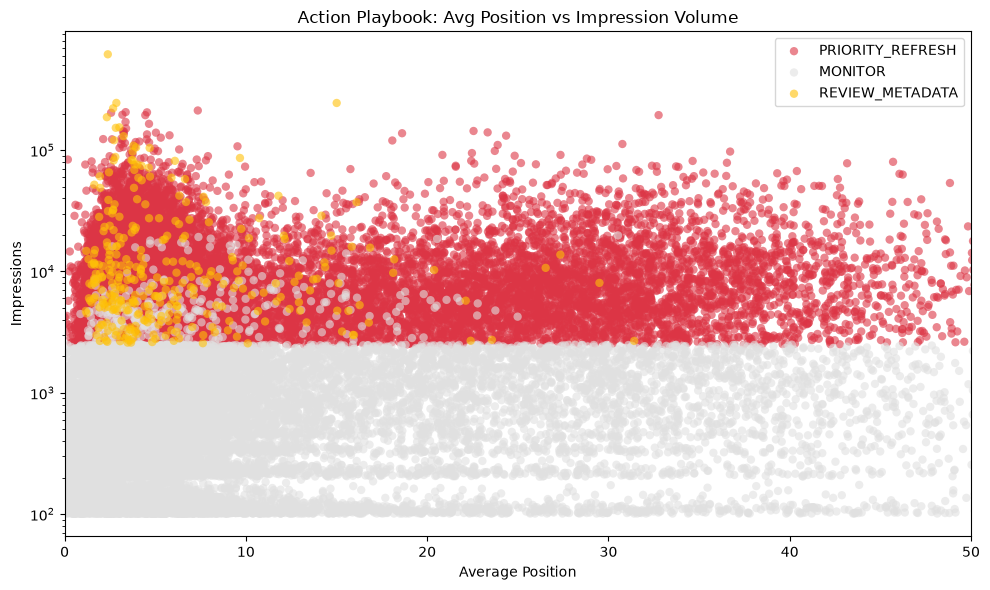

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# 1. Export the Data
os.makedirs('../../work/outputs', exist_ok=True)
csv_out = '../../work/outputs/final_action_queue.csv'
df_queue.to_csv(csv_out, index=False)
print(f"Queue exported to: {csv_out}")

# 2. Export the Figure
os.makedirs('../../work/figures', exist_ok=True)
plt.figure(figsize=(10, 6))

# Plot Monitor (Gray), Review (Yellow), Priority (Red)
colors = {'MONITOR': '#e0e0e0', 'REVIEW_METADATA': '#ffc107', 'PRIORITY_REFRESH': '#dc3545'}

for action in df_playbook['action'].unique():
    subset = df_playbook[df_playbook['action'] == action]
    plt.scatter(subset['position'], subset['impressions'], c=colors[action], label=action, alpha=0.6, edgecolors='none')

plt.title('Action Playbook: Avg Position vs Impression Volume')
plt.xlabel('Average Position')
plt.ylabel('Impressions')
plt.xlim(0, 50) # Zoom in on the relevant top 50 positions
plt.yscale('log') # Log scale for massive impression variance
plt.legend()
plt.tight_layout()

fig_out = '../../work/figures/playbook_scatter.png'
plt.savefig(fig_out)
print(f"Figure exported to: {fig_out}")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.